# Milestone 3: Low-Rank Prediction with the SVD
Project 2: A Movie Recommendation System. MATH 344L

## Part A: Load project functions and data

In [1]:
import os
import subprocess
import sys

USER = 'algalda'
REPO = 'MATH-344L-project'

if os.path.exists(REPO):
    subprocess.run(['git', '-C', REPO, 'pull'], check=True)
else:
    subprocess.run(
        ['git', 'clone', f'https://github.com/{USER}/{REPO}.git', REPO],
        check=True)

sys.path.insert(0, f'{REPO}/src')
from evaluate import split_ratings, to_matrix, rmse
from models import bias_baseline

Already up to date.


- clones our GitHub repo into Colab (or pulls the newest version if it's already there)
- adds `src/` to Python's search path so we can import our Milestone 2 functions

In [2]:
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if not os.path.exists('ml-100k'):
    urllib.request.urlretrieve(
        'https://files.grouplens.org/datasets/movielens/ml-100k.zip',
        'ml-100k.zip')
    zipfile.ZipFile('ml-100k.zip').extractall()

ratings = pd.read_csv(
    'ml-100k/u.data', sep='\t',
    names=['user', 'item', 'rating', 'time'])

train, test = split_ratings(ratings, seed=0)
fit, val = split_ratings(train, seed=1)
print('fit:', len(fit), 'validation:', len(val), 'test:', len(test))

fit: 81200 validation: 8832 test: 9968


- downloads MovieLens 100K and loads the ratings
- first split: train / test (test is hidden until the very end)
- second split: splits train into fit (to build models) and validation (to pick settings)

## Part B: Set up a fair validation comparison

In [3]:
R_fit = to_matrix(fit)
known_fit = ~np.isnan(R_fit)
val_truth = val['rating'].to_numpy()
val_u = val['user'].to_numpy() - 1
val_i = val['item'].to_numpy() - 1

def score_at(P, rows, cols, truth):
    """RMSE for selected entries of a prediction matrix."""
    pred = np.clip(P[rows, cols], 1, 5)
    return rmse(pred, truth)

- builds the user-by-movie matrix from the fit ratings only
- stores the true validation ratings and their row/column positions
- `score_at` pulls one prediction per validation pair, clips to 1–5 stars, and returns RMSE

## Part C: Baseline prediction matrix

In [4]:
def baseline_matrix(R):
    """Full matrix: overall mean plus user and movie effects."""
    mu, b_user, b_item = bias_baseline(R)
    return mu + b_user[:, None] + b_item[None, :]

B_fit = baseline_matrix(R_fit)
baseline_val_rmse = score_at(B_fit, val_u, val_i, val_truth)
print('Baseline validation RMSE:', round(baseline_val_rmse, 4))

Baseline validation RMSE: 0.9731


- turns the Milestone 2 bias baseline into a full 943 × 1682 prediction matrix
- broadcasting adds the user column and movie row to get a prediction for every pair
- this is the validation score the SVD models have to beat

## Part D: Rank-k helper

In [5]:
def rank_k(U, s, Vt, k):
    """Build a rank-k matrix from an already computed SVD."""
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

- keeps the first k singular values/vectors and multiplies them back together
- takes an SVD that's already computed, so we only run the SVD once per model

## Part E: Model 1, fill gaps with movie averages

In [6]:
mu_fit = np.nanmean(R_fit)
n_item = known_fit.sum(axis=0)
item_mean = np.full(R_fit.shape[1], mu_fit)
has_rating = n_item > 0
item_mean[has_rating] = (
    np.nansum(R_fit, axis=0)[has_rating] / n_item[has_rating])

F = np.where(known_fit, R_fit, item_mean[None, :])
U1, s1, Vt1 = np.linalg.svd(F, full_matrices=False)

- SVD needs a complete matrix, so each missing rating is filled with that movie's average
- movies with no fit ratings fall back to the overall mean
- takes the SVD of the filled matrix `F`

## Part F: Model 2, SVD of what the baseline misses

In [7]:
X_fit = np.where(known_fit, R_fit - B_fit, 0.0)
U2, s2, Vt2 = np.linalg.svd(X_fit, full_matrices=False)

- at known entries: how far the actual rating is from the baseline
- at gaps: 0 (no observed deviation)
- the SVD looks for patterns in those leftovers; predictions = baseline + low-rank deviations

## Part G: Choose rank using validation RMSE

In [8]:
ks = [1, 2, 3, 5, 10, 15, 20, 30, 50, 100]
val_err1, val_err2 = [], []

for k in ks:
    P1 = rank_k(U1, s1, Vt1, k)
    P2 = rank_k(U2, s2, Vt2, k) + B_fit
    val_err1.append(score_at(P1, val_u, val_i, val_truth))
    val_err2.append(score_at(P2, val_u, val_i, val_truth))

best_k1 = ks[int(np.argmin(val_err1))]
best_k2 = ks[int(np.argmin(val_err2))]
print('Best Model 1 k:', best_k1, 'validation RMSE:', min(val_err1))
print('Best Model 2 k:', best_k2, 'validation RMSE:', min(val_err2))

Best Model 1 k: 15 validation RMSE: 0.9934477108911386
Best Model 2 k: 15 validation RMSE: 0.9492241710885614


- tries each rank for both models and scores on validation
- `np.argmin` finds the rank with the smallest validation error
- Model 2 adds `B_fit` back since its SVD is of deviations, not star ratings

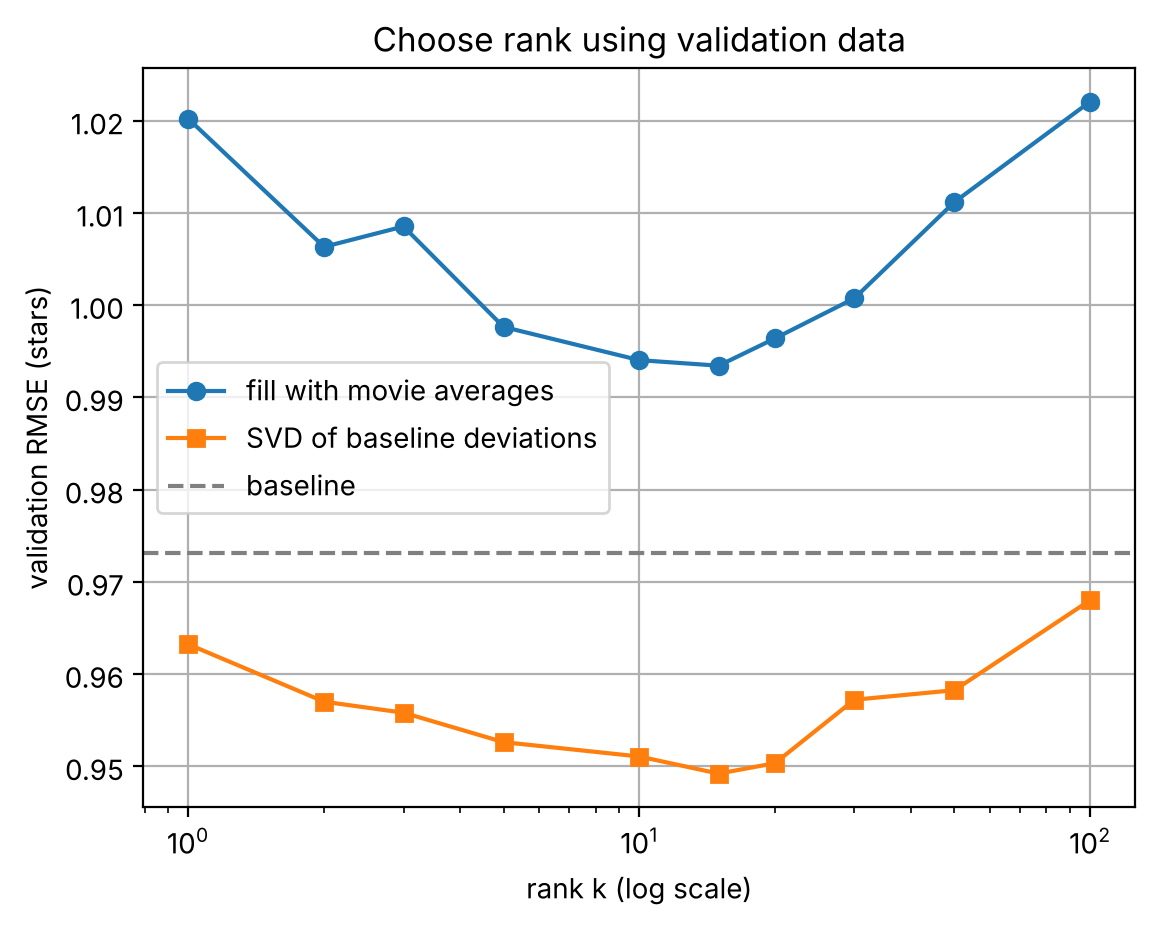

In [9]:
plt.semilogx(ks, val_err1, 'o-', label='fill with movie averages')
plt.semilogx(ks, val_err2, 's-', label='SVD of baseline deviations')
plt.axhline(baseline_val_rmse, color='gray', linestyle='--',
            label='baseline')
plt.xlabel('rank k (log scale)')
plt.ylabel('validation RMSE (stars)')
plt.title('Choose rank using validation data')
plt.grid()
plt.legend()
plt.savefig('validation_rmse_vs_k.png', dpi=150)
plt.show()

- Model 2 (orange) is below the baseline at every rank; best at k = 15
- Model 1 (blue) is above the baseline at every rank, so filling with movie averages never beats the simple baseline
- both curves go up again for large k: extra ranks start fitting noise instead of real taste patterns
- figure saved as `validation_rmse_vs_k.png`

## Part H: Model 3, iteratively improve the missing-value guesses

In [10]:
def iterative_svd_predict(R, k, n_iter=10):
    """Predict ratings by repeatedly imputing missing deviations."""
    known = ~np.isnan(R)
    B = baseline_matrix(R)
    X = np.where(known, R - B, 0.0)

    for _ in range(n_iter):
        U, s, Vt = np.linalg.svd(X, full_matrices=False)
        L = rank_k(U, s, Vt, k)
        X = np.where(known, R - B, L)

    return L + B

- starts like Model 2 (gaps = 0)
- each round: take a rank-k SVD, put its guesses into the gaps, keep the real deviations fixed
- after `n_iter` rounds, adds the baseline back

In [11]:
ks_iter = [2, 5, 10, 20]
val_err3 = []

for k in ks_iter:
    P3 = iterative_svd_predict(R_fit, k, n_iter=10)
    val_err3.append(score_at(P3, val_u, val_i, val_truth))

best_k3 = ks_iter[int(np.argmin(val_err3))]
print('Best iterative rank:', best_k3)
print('Best validation RMSE:', min(val_err3))

Best iterative rank: 2
Best validation RMSE: 0.9431464026691649


- tries 4 ranks for Model 3 (each one needs 10 SVDs, so fewer ranks)
- picks the rank with the lowest validation RMSE

In [12]:
summary = pd.Series({
    'baseline': baseline_val_rmse,
    f'Model 1 (k={best_k1})': min(val_err1),
    f'Model 2 (k={best_k2})': min(val_err2),
    f'Model 3 (k={best_k3})': min(val_err3),
}, name='validation RMSE')
print(summary.round(4).sort_values())

Model 3 (k=2)     0.9431
Model 2 (k=15)    0.9492
baseline          0.9731
Model 1 (k=15)    0.9934
Name: validation RMSE, dtype: float64


- Model 3 (iterative SVD, k = 2) has the lowest validation RMSE, about 0.943
- Model 2 is next at 0.949, then the baseline at 0.973
- Model 1 is worse than the baseline
- based on validation only, we pick Model 3 with k = 2

## Part I: Refit and evaluate on the test set once

In [13]:
R_train = to_matrix(train)
test_truth = test['rating'].to_numpy()
test_u = test['user'].to_numpy() - 1
test_i = test['item'].to_numpy() - 1

B_train = baseline_matrix(R_train)
test_baseline = score_at(B_train, test_u, test_i, test_truth)

if min(val_err3) < min(val_err2) and min(val_err3) < min(val_err1):
    test_prediction = iterative_svd_predict(
        R_train, best_k3, n_iter=10)
    chosen_model = 'iterative SVD'
elif min(val_err2) < min(val_err1):
    known_train = ~np.isnan(R_train)
    X_train = np.where(known_train, R_train - B_train, 0.0)
    U, s, Vt = np.linalg.svd(X_train, full_matrices=False)
    test_prediction = rank_k(U, s, Vt, best_k2) + B_train
    chosen_model = 'baseline plus low-rank deviations'
else:
    known_train = ~np.isnan(R_train)
    mu_train = np.nanmean(R_train)
    n_item_train = known_train.sum(axis=0)
    means_train = np.full(R_train.shape[1], mu_train)
    has_train = n_item_train > 0
    means_train[has_train] = (
        np.nansum(R_train, axis=0)[has_train] / n_item_train[has_train])
    F_train = np.where(known_train, R_train, means_train[None, :])
    U, s, Vt = np.linalg.svd(F_train, full_matrices=False)
    test_prediction = rank_k(U, s, Vt, best_k1)
    chosen_model = 'SVD of movie-average-filled matrix'

test_rmse = score_at(test_prediction, test_u, test_i, test_truth)
print('Chosen model:', chosen_model)
print('Baseline test RMSE:', round(test_baseline, 4))
print('Chosen model test RMSE:', round(test_rmse, 4))

Chosen model: iterative SVD
Baseline test RMSE: 0.9545
Chosen model test RMSE: 0.9286


- rebuilds the matrix from all of `train` (fit + validation)
- picks whichever model had the lowest validation RMSE and refits it with its chosen rank
- scores once on the hidden test set; we don't go back and change anything based on this number

## Part J: Make a few recommendations

In [14]:
item_info = pd.read_csv(
    'ml-100k/u.item', sep='|', header=None, usecols=[0, 1],
    encoding='latin-1')
item_info.columns = ['item', 'title']

user_id = 1
user_row = user_id - 1
unrated = np.where(np.isnan(R_train[user_row]))[0]
predicted_scores = np.clip(test_prediction[user_row], 1, 5)
top = unrated[np.argsort(predicted_scores[unrated])[-5:][::-1]]

for col in top:
    title = item_info.loc[item_info['item'] == col + 1, 'title'].iloc[0]
    print(title, 'predicted rating:', round(predicted_scores[col], 2))

Great Day in Harlem, A (1994) predicted rating: 5.0
Aiqing wansui (1994) predicted rating: 5.0
Santa with Muscles (1996) predicted rating: 5.0
Saint of Fort Washington, The (1993) predicted rating: 5.0
Pulp Fiction (1994) predicted rating: 5.0


- loads movie titles
- finds the movies user 1 hasn't rated in training
- sorts them by predicted score and prints the top 5 (column + 1 = MovieLens movie ID)

# Practice Exercises

### Exercise 1: Does filling matter?

In [15]:
def fill_and_score(fill_vec, ranks):
    """Model 1 with a chosen per-movie fill value; validation RMSE at each rank."""
    F_ = np.where(known_fit, R_fit, fill_vec[None, :])
    U_, s_, Vt_ = np.linalg.svd(F_, full_matrices=False)
    return [score_at(rank_k(U_, s_, Vt_, k), val_u, val_i, val_truth)
            for k in ranks]

ks_fill = [2, 5, 10, 20, 50]
n_cols = R_fit.shape[1]
fills = {
    'movie average': item_mean,
    'overall average': np.full(n_cols, mu_fit),
    '3 stars': np.full(n_cols, 3.0),
    '0 stars': np.zeros(n_cols),
}
fill_table = pd.DataFrame(
    {name: fill_and_score(v, ks_fill) for name, v in fills.items()},
    index=pd.Index(ks_fill, name='rank k'))
print(fill_table.round(4))

        movie average  overall average  3 stars  0 stars
rank k                                                  
2              1.0063           1.0728   1.1192   2.4912
5              0.9976           1.0568   1.0856   2.4036
10             0.9940           1.0511   1.0749   2.3434
20             0.9964           1.0545   1.0788   2.3508
50             1.0112           1.0716   1.1210   2.4913


**Which fill works best?** Movie average wins at every rank (best ≈ 0.994 at k = 10). Overall average is next (≈ 1.05), then 3 stars (≈ 1.07). The movie average is the most informative guess because movies really do differ in typical rating, which was the movie-average baseline result from Milestone 2. A constant fill tells the SVD nothing about which movies are good.

None of these fills beats the plain baseline (0.973), though. The roughly 94% filled-in entries dominate the SVD, so it mostly learns the fill values instead of real preferences.

**Why 0 stars is a bad idea:** RMSE is about 2.4. 0 isn't even a valid rating, and filling with 0 treats "hasn't watched it" as "hated it." Since most entries are missing, the SVD mostly learns which user/movie pairs are *rated vs. not rated*, and its predictions get pulled way down toward 0.

### Exercise 2: The full-rank check

In [16]:
k_full = len(s2)
L_full = rank_k(U2, s2, Vt2, k_full)
P2_full = L_full + B_fit

print('Full rank k =', k_full)
print('Reconstructs X_fit exactly?', np.allclose(L_full, X_fit))
print('Largest |deviation| at validation gaps:',
      np.abs(L_full[val_u, val_i]).max())
print('Full-rank validation RMSE:',
      round(score_at(P2_full, val_u, val_i, val_truth), 4))
print('Baseline validation RMSE: ',
      round(baseline_val_rmse, 4))

Full rank k = 943
Reconstructs X_fit exactly? True
Largest |deviation| at validation gaps: 1.0473176145775476e-14
Full-rank validation RMSE: 0.9731
Baseline validation RMSE:  0.9731


- At full rank (k = 943) the SVD rebuilds `X_fit` exactly (`allclose` is True), because keeping every singular value loses nothing.
- `X_fit` was 0 at every gap, so the rebuilt deviation at every validation entry is 0 (up to about 1e-14 rounding).
- Predictions are then baseline + 0 = baseline, and the validation RMSE matches the baseline exactly (0.9731).
- This doesn't mean it learned anything. It just copied the training data back, including the zeros we made up. The low-rank model only helps because truncating to small k *forces* it to fill gaps from shared patterns across users and movies, not from our placeholder 0s.

### Exercise 3: Does more iteration help?

In [17]:
iters = [1, 2, 5, 10, 20]
iter_err = [score_at(iterative_svd_predict(R_fit, 5, n_iter=t),
                     val_u, val_i, val_truth) for t in iters]
print(pd.Series(iter_err, index=pd.Index(iters, name='n_iter'),
                name='validation RMSE (k=5)').round(4))

n_iter
1     0.9526
2     0.9456
5     0.9411
10    0.9433
20    0.9484
Name: validation RMSE (k=5), dtype: float64


- With k = 5: 1 round 0.9526, 2 rounds 0.9456, 5 rounds 0.9411 (best), 10 rounds 0.9433, 20 rounds 0.9484
- **No, more iteration doesn't always help.** The first few rounds improve a lot because the 0 placeholders get replaced with real low-rank guesses. After about 5 rounds the error goes back up: the model keeps fitting its own guesses more tightly to the training ratings and starts overfitting.
- So `n_iter` is a setting like k, and ideally it would also be picked with validation data.

### Exercise 4: Check for overfitting

In [18]:
print('Model 2 validation RMSE by rank:')
print(pd.Series(val_err2, index=pd.Index(ks, name='k')).round(4))
print()
print('Model 3 validation RMSE by rank:')
print(pd.Series(val_err3, index=pd.Index(ks_iter, name='k')).round(4))
print()
print('Chosen model:', chosen_model)
print('Best validation RMSE:', round(min(min(val_err1), min(val_err2), min(val_err3)), 4))
print('Final test RMSE:     ', round(test_rmse, 4))

Model 2 validation RMSE by rank:
k
1      0.9632
2      0.9570
3      0.9558
5      0.9526
10     0.9511
15     0.9492
20     0.9504
30     0.9572
50     0.9583
100    0.9680
dtype: float64

Model 3 validation RMSE by rank:
k
2     0.9431
5     0.9433
10    0.9588
20    0.9769
dtype: float64

Chosen model: iterative SVD
Best validation RMSE: 0.9431
Final test RMSE:      0.9286


- Validation error vs. rank is U-shaped: Model 2 drops from 0.963 (k = 1) to 0.949 (k = 15), then rises to 0.968 (k = 100). Small k underfits; large k starts memorizing noise in the fit ratings. That's overfitting.
- The final test RMSE (0.929) is a bit lower than the best validation RMSE (0.943). That's reasonable: the final model was refit on all of `train` (about 11% more ratings than `fit`), and the test and validation sets are different random samples. The numbers are close, so there's no sign we overfit our model choice.
- **Why pick the rank before looking at test:** if we tried ranks on the test set and kept the best one, the test score would be optimistic (the same leakage problem as the "cheating" exercise in Milestone 2). The test set only stays an honest estimate of performance on unseen ratings if it's used once, after every decision is made.

### Exercise 5: Cold start

In [19]:
import warnings

# Pretend a brand-new user signs up: add an all-missing row.
R_new = np.vstack([R_train, np.full((1, R_train.shape[1]), np.nan)])
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)  # mean of an empty row
    mu_n, b_user_n, b_item_n = bias_baseline(R_new)
print('New user effect b_user:', b_user_n[-1])

# Sensible fallback: treat the new user as average (b_user = 0).
fallback = mu_n + b_item_n
top_new = np.argsort(fallback)[-5:][::-1]
for col in top_new:
    title = item_info.loc[item_info['item'] == col + 1, 'title'].iloc[0]
    n = int((~np.isnan(R_train[:, col])).sum())
    print(f'{title}  score={fallback[col]:.2f}  ({n} training ratings)')

New user effect b_user: nan
Great Day in Harlem, A (1994)  score=5.43  (1 training ratings)
Aiqing wansui (1994)  score=5.27  (1 training ratings)
Santa with Muscles (1996)  score=5.02  (2 training ratings)
Saint of Fort Washington, The (1993)  score=4.99  (2 training ratings)
Someone Else's America (1995)  score=4.90  (1 training ratings)


- A new user has an all-NaN row, so their user effect is `nan` (the mean of nothing). Every prediction for them would be `nan`, and the SVD can't find a pattern for someone with no ratings.
- The best fallback is to treat them as an average user (b_user = 0) and predict μ + b_item. But that just recommends the same movies to everyone, and the top ones here are obscure films with only 1–2 training ratings, so their movie effect is based on almost no data.
- **What would help:**
  - ask new users to rate a few popular movies at sign-up
  - use demographic info (MovieLens has age, gender and occupation in `u.user`)
  - use movie genre info (`u.item`)
  - recommend by popularity (many ratings and a high average) until they've rated some movies

### Exercise 6: Explain the result

- **Baseline (test RMSE 0.954):** overall mean + user effect + movie effect is typically off by just under 1 star. That's the bar to beat.
- **Chosen model (iterative SVD, k = 2, test RMSE 0.929):** about 0.026 stars better (≈ 2.7%). That's a real but modest improvement, and it came from the low-rank structure: a couple of hidden taste factors explain some of what the baseline misses. Model 2 also beat the baseline on validation, but filling gaps with movie averages (Model 1) didn't.
- **What the recommendations do tell us:** which unrated movies the model scores highest for user 1.
- **What they don't tell us:** whether user 1 would actually like them. RMSE is an average over about 10,000 hidden ratings, not proof for any one prediction. The top picks are mostly obscure movies with very few ratings. They score 5 stars mostly because of a large movie effect from 1–2 ratings, so they're weak recommendations. A real system would shrink effects for movies with few ratings or require a minimum number of ratings before recommending.